# Strategic Form Audit
## tl;dr
El contraste externo recupera 5/5 puntos regulares. La enumeración de vértices externa falla en indiferencia total; no se confunde fallo con ausencia de equilibrio. Una tolerancia ex ante puede ocultar una desviación interina grande.

## Context & Methods
Dos prestamistas, estado y señales binarias, u_i=a_i(theta+alpha*a_j-c). Forma estratégica ex ante 4x4 calculada por suma de ocho estados. Nashpy 0.0.43 es externo; el poliedro racional existente es baseline.
### Key Assumptions
Señales condicionalmente independientes, prior interior, aleatorización independiente entre jugadores, sin datos reales ni identificación. La proyección conserva marginales por tipo, no correlaciones entre acciones contrafactuales.

In [1]:
import csv,json
from pathlib import Path
print(json.loads(Path('results/config.json').read_text())['regular'])
print(json.loads(Path('results/metadata.json').read_text()))

{'prior': 0.5, 'accuracy': 0.8, 'cost': 0.9, 'complementarity': 0.8}
{'seed': 20261016, 'python': '3.12.14', 'machine': 'x86_64', 'platform': 'Linux-6.18.44-x86_64-with-glibc2.39', 'cpu': 'x86_64', 'nashpy': '0.0.43', 'numpy': '2.3.5', 'source_commit': '681836e', 'memory': 'tracemalloc peak Python allocations, excludes native RSS', 'threshold': 1e-08, 'hashes': {'timing.csv': '550d3425ef78554083280ea3749d32d84e42bd626b5e624b2cbc2af1308a0525', 'equilibria.csv': '9384acdf229993c061ac302a38320dd470f9988f30ef22af50d6176320ff2037', 'rare_type_ablation.csv': '6c71c0858289706303f77a8217344751e99b56fabcf4416258fd91bb9dfca691', 'summary.csv': 'bd4c104f7d03f501953627d047cc038928899c5f968520fce7e9b401a4ce6b99', 'stability.csv': 'c9c4cf917cd4af697ad294e6c505873543160180d66e02b5d1979b1a8f2e3f86'}}


## Data
Payoffs sintéticos racionales exportados a .nfg. Orden de políticas: (0,0),(0,1),(1,0),(1,1); jugador uno varía más rápido. No se ejecutó Gambit; round-trip usa un parser limitado propio y Nashpy consume sus matrices.

In [2]:
print(Path('results/regular.nfg').read_text())

NFG 1 R "Bayesian credit freeze" { "Lender 0" "Lender 1" } { 4 4 }

0 0 -1/20 0 -7/20 0 -2/5 0 0 -1/20 111/500 111/500 -111/500 39/500 0 7/20 0 -7/20 39/500 -111/500 -39/500 -39/500 0 1/20 0 -2/5 7/20 0 1/20 0 2/5 2/5



## Results
La tabla cuenta vértices del baseline encontrados a tolerancia 1e-8; una lista finita no representa una familia continua completa.

In [3]:
for row in list(csv.DictReader(Path('results/summary.csv').open()))[:8]:
    print({k:row[k] for k in ['scenario','method','target_vertices','matched_vertices','max_interim_regret','status']})

{'scenario': 'regular', 'method': 'vertex_enumeration', 'target_vertices': '5', 'matched_vertices': '5', 'max_interim_regret': '3.6245516392174193e-16', 'status': 'ok'}
{'scenario': 'regular', 'method': 'support_enumeration', 'target_vertices': '5', 'matched_vertices': '5', 'max_interim_regret': '3.398017161766334e-17', 'status': 'ok'}
{'scenario': 'coordination_family', 'method': 'vertex_enumeration', 'target_vertices': '6', 'matched_vertices': '6', 'max_interim_regret': '0.0', 'status': 'ok'}
{'scenario': 'coordination_family', 'method': 'support_enumeration', 'target_vertices': '6', 'matched_vertices': '6', 'max_interim_regret': '0.0', 'status': 'ok'}
{'scenario': 'full_indifference', 'method': 'vertex_enumeration', 'target_vertices': '16', 'matched_vertices': '0', 'max_interim_regret': '', 'status': "TypeError: 'NoneType' object is not subscriptable"}
{'scenario': 'full_indifference', 'method': 'support_enumeration', 'target_vertices': '16', 'matched_vertices': '16', 'max_interim_r

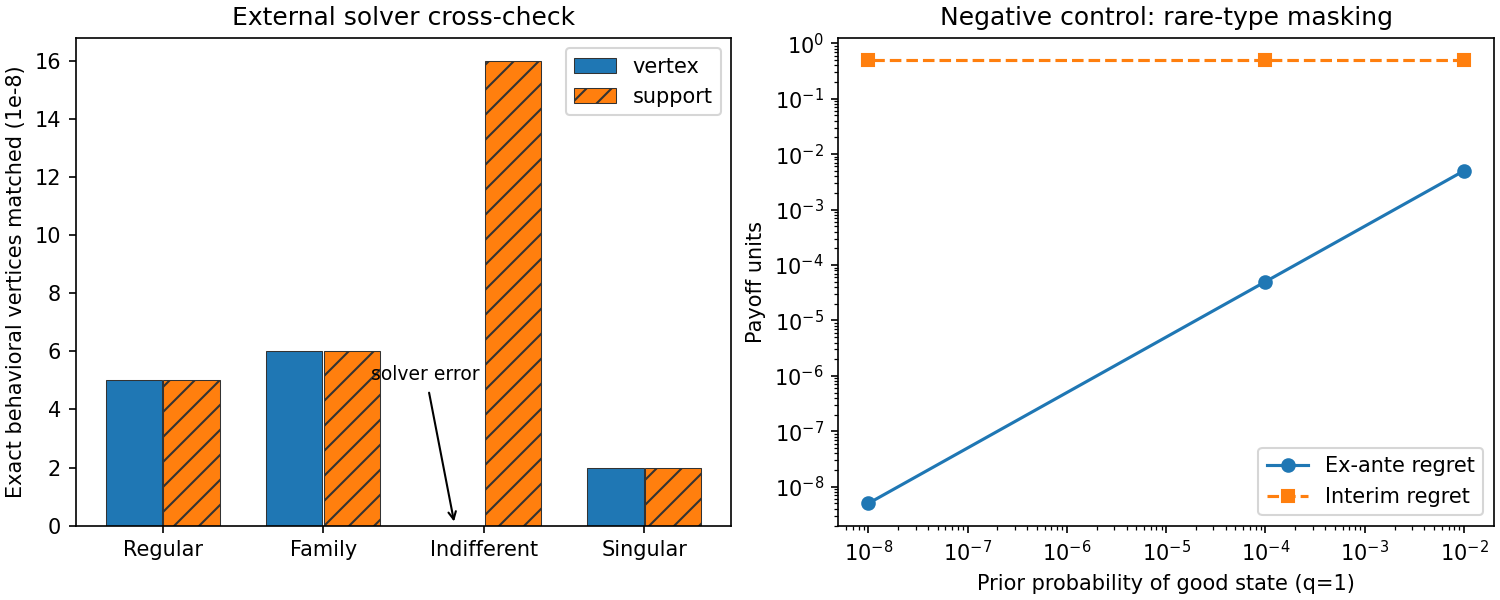

In [4]:
from IPython.display import Image,display
display(Image(filename='results/comparison.png'))

In [5]:
print(Path('results/rare_type_ablation.csv').read_text())
print(Path('results/coverage.txt').read_text())

prior,strategic_regret,interim_regret
0.01,0.005,0.5
0.0001,5e-05,0.5
1e-08,5e-09,0.5

Name               Stmts   Miss Branch BrPart  Cover   Missing
--------------------------------------------------------------
src/strategic.py      55      0     14      0   100%
--------------------------------------------------------------
TOTAL                 55      0     14      0   100%



## Takeaways
Validar regret condicional por tipo y conservar familias poliédricas: menor regret ex ante no certifica por sí solo un equilibrio interino aproximado uniforme. Cobertura medida sólo de src/ nuevo; pruebas no equivalen a demostración de completitud. Ver informe.md y referencias.bib para límites y literatura.